# Modelos de Regresión con Scikit-Learn

conceptualización, entrenamiento, evaluación y comparación de modelos de regresión supervisada usando Python y Scikit-Learn.

## 1. Conceptualización de un Problema de Regresión

La regresión es una técnica de aprendizaje supervisado cuyo objetivo es predecir un valor continuo a partir de una o más variables de entrada (características).

**Ejemplo:** Predecir el precio de una casa según su tamaño.

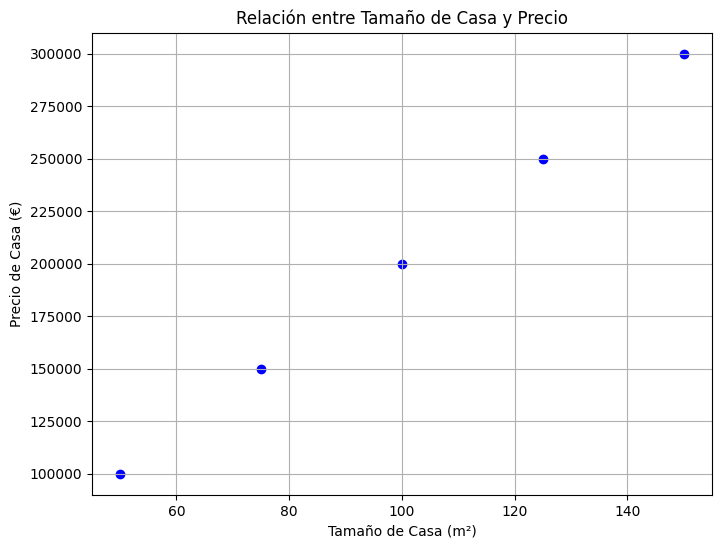

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Datos sintéticos: tamaño de casa (m²) y precio (€)
tamaño_casa = np.array([50, 75, 100, 125, 150]).reshape(-1, 1)
precio_casa = np.array([100000, 150000, 200000, 250000, 300000])

plt.figure(figsize=(8, 6))
plt.scatter(tamaño_casa, precio_casa, color='blue')
plt.title('Relación entre Tamaño de Casa y Precio')
plt.xlabel('Tamaño de Casa (m²)')
plt.ylabel('Precio de Casa (€)')
plt.grid(True)
plt.show()

## 2. Regresión Lineal con Scikit-Learn

La regresión lineal busca ajustar una línea recta a los datos para modelar la relación entre la variable independiente y la dependiente.

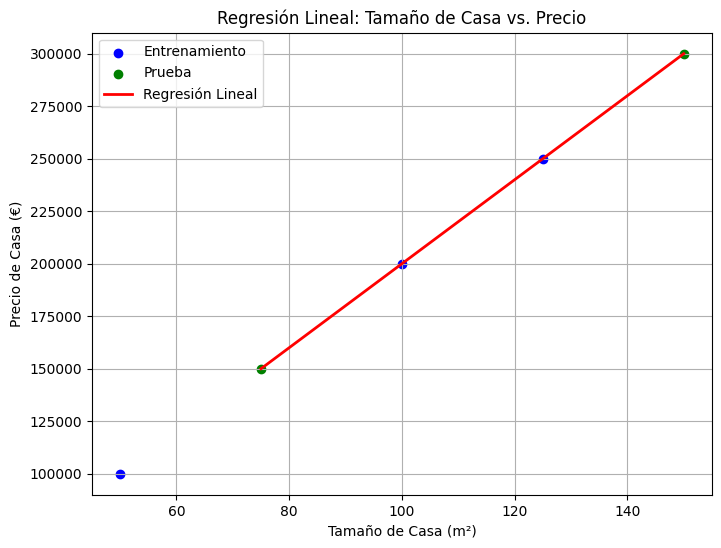

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# División de datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(tamaño_casa, precio_casa, test_size=0.3, random_state=42)

# Entrenamiento del modelo
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

# Predicciones
y_pred_lineal = modelo_lineal.predict(X_test)

# Visualización
plt.figure(figsize=(8, 6))
plt.scatter(X_train, y_train, color='blue', label='Entrenamiento')
plt.scatter(X_test, y_test, color='green', label='Prueba')
plt.plot(X_test, y_pred_lineal, color='red', linewidth=2, label='Regresión Lineal')
plt.title('Regresión Lineal: Tamaño de Casa vs. Precio')
plt.xlabel('Tamaño de Casa (m²)')
plt.ylabel('Precio de Casa (€)')
plt.legend()
plt.grid(True)
plt.show()

## 3. Regresión No Lineal y Herramientas Avanzadas

Cuando la relación entre variables no es lineal, se pueden usar transformaciones polinómicas y modelos avanzados como Ridge, Lasso y SVR.

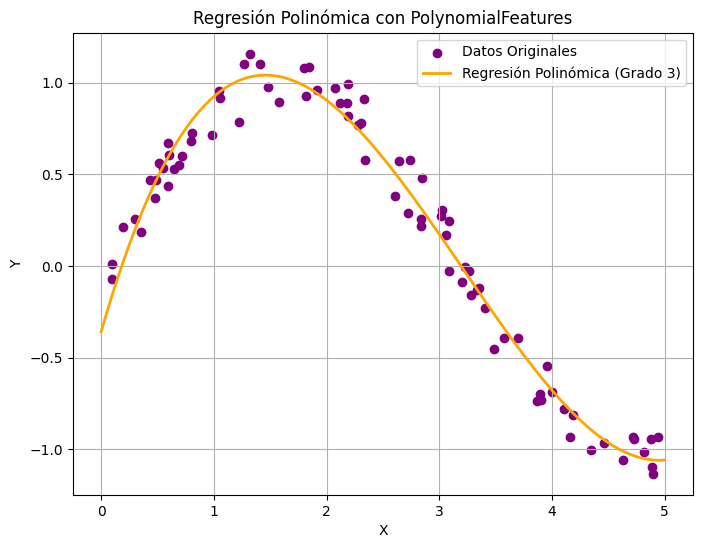

In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Datos sintéticos no lineales
grado_polinomio = 3
np.random.seed(0)
X_nonlinear = np.sort(5 * np.random.rand(80, 1), axis=0)
y_nonlinear = np.sin(X_nonlinear).ravel() + np.random.normal(0, 0.1, X_nonlinear.shape[0])

# Modelo polinómico
tuberia_poly = make_pipeline(PolynomialFeatures(degree=grado_polinomio), LinearRegression())
tuberia_poly.fit(X_nonlinear, y_nonlinear)

# Predicción y visualización
X_test_poly = np.linspace(0, 5, 100).reshape(-1, 1)
y_pred_poly = tuberia_poly.predict(X_test_poly)

plt.figure(figsize=(8, 6))
plt.scatter(X_nonlinear, y_nonlinear, color='purple', label='Datos Originales')
plt.plot(X_test_poly, y_pred_poly, color='orange', linewidth=2, label=f'Regresión Polinómica (Grado {grado_polinomio})')
plt.title('Regresión Polinómica con PolynomialFeatures')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

## 4. Entrenamiento y Evaluación de Modelos de Regresión

El proceso incluye preprocesamiento, división de datos, entrenamiento y evaluación usando métricas como MSE, R² y MAE.

In [4]:
from sklearn.metrics import mean_squared_error, r2_score

# Datos sintéticos para evaluación
np.random.seed(42)
X_demo = np.random.rand(100, 1) * 10
y_demo = 2 * X_demo + 1 + np.random.randn(100, 1) * 2

# División de datos
X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(X_demo, y_demo, test_size=0.2, random_state=42)

# Entrenamiento y predicción
model_eval = LinearRegression()
model_eval.fit(X_train_demo, y_train_demo)
y_pred_eval = model_eval.predict(X_test_demo)

# Métricas de evaluación
mse = mean_squared_error(y_test_demo, y_pred_eval)
r2 = r2_score(y_test_demo, y_pred_eval)
mae = np.mean(np.abs(y_test_demo - y_pred_eval))

print(f"Error Cuadrático Medio (MSE): {mse:.2f}")
print(f"Coeficiente de Determinación (R²): {r2:.2f}")
print(f"Error Absoluto Medio (MAE): {mae:.2f}")

Error Cuadrático Medio (MSE): 2.61
Coeficiente de Determinación (R²): 0.93
Error Absoluto Medio (MAE): 1.18


## 5. Predicciones y Selección del Modelo Óptimo

Una vez entrenado el modelo, se pueden hacer predicciones y analizar criterios para seleccionar el modelo más adecuado según métricas y complejidad.

In [5]:
# Predicción con el modelo lineal entrenado
nueva_casa_tamaño = np.array([[110]])
precio_predicho = modelo_lineal.predict(nueva_casa_tamaño)
print(f"Para una casa de {nueva_casa_tamaño[0,0]} m², el precio predicho es: {precio_predicho[0]:.2f} €")

# Criterios para seleccionar el modelo óptimo
from sklearn.metrics import r2_score
print("\nCriterios para selección de modelo óptimo:")
print("1. Analizar la linealidad de los datos.")
print("2. Evaluar la complejidad y capacidad predictiva.")
print("3. Aplicar regularización si hay riesgo de sobreajuste.")
print("4. Medir el rendimiento con métricas como MSE y R².")
print("5. Considerar la interpretabilidad del modelo.")
print(f"R² del modelo lineal en prueba: {r2_score(y_test, modelo_lineal.predict(X_test)):.2f}")

Para una casa de 110 m², el precio predicho es: 220000.00 €

Criterios para selección de modelo óptimo:
1. Analizar la linealidad de los datos.
2. Evaluar la complejidad y capacidad predictiva.
3. Aplicar regularización si hay riesgo de sobreajuste.
4. Medir el rendimiento con métricas como MSE y R².
5. Considerar la interpretabilidad del modelo.
R² del modelo lineal en prueba: 1.00


## 6. Actividad Práctica Guiada: Comparación de Modelos de Regresión

En esta actividad se generan datos sintéticos no lineales, se dividen en entrenamiento y prueba, se aplican varios modelos de regresión y se comparan sus resultados usando métricas de evaluación.

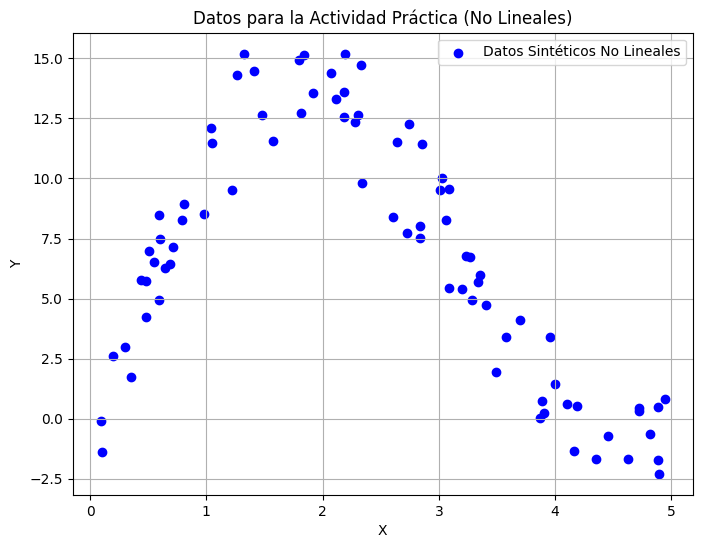

Linear Regression: MSE = 24.55, R² = 0.13
Polynomial Regression (degree=2): MSE = 7.73, R² = 0.72
Polynomial Regression (degree=5): MSE = 1.96, R² = 0.93
Ridge Regression: MSE = 24.53, R² = 0.13
Lasso Regression: MSE = 24.48, R² = 0.13
SVR (RBF Kernel): MSE = 2.21, R² = 0.92

El modelo con el mejor MSE es: Polynomial Regression (degree=5)
MSE: 1.96, R²: 0.93


In [6]:
import pandas as pd
from sklearn.linear_model import Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

# Datos sintéticos no lineales para la actividad
np.random.seed(0)
X_actividad = np.sort(5 * np.random.rand(80, 1), axis=0)
noise = np.random.normal(0, 1.5, X_actividad.shape[0])
y_actividad = (np.sin(X_actividad).ravel() * 10 + X_actividad.ravel() * 2 + noise)

plt.figure(figsize=(8, 6))
plt.scatter(X_actividad.ravel(), y_actividad.ravel(), color='blue', label='Datos Sintéticos No Lineales')
plt.title('Datos para la Actividad Práctica (No Lineales)')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.legend()
plt.show()

# División de datos
X_train_act, X_test_act, y_train_act, y_test_act = train_test_split(X_actividad, y_actividad, test_size=0.3, random_state=42)

# Modelos a comparar
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (degree=2)": Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression())]),
    "Polynomial Regression (degree=5)": Pipeline([('poly', PolynomialFeatures(degree=5)), ('linear', LinearRegression())]),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),
    "SVR (RBF Kernel)": SVR(kernel='rbf', C=100, gamma=0.1)
}

results = {}
for name, model in models.items():
    model.fit(X_train_act, y_train_act)
    y_pred = model.predict(X_test_act)
    mse = mean_squared_error(y_test_act, y_pred)
    r2 = r2_score(y_test_act, y_pred)
    results[name] = {"MSE": mse, "R2": r2}
    print(f"{name}: MSE = {mse:.2f}, R² = {r2:.2f}")

# Selección del mejor modelo
best_model_name = min(results, key=lambda k: results[k]['MSE'])
print(f"\nEl modelo con el mejor MSE es: {best_model_name}")
print(f"MSE: {results[best_model_name]['MSE']:.2f}, R²: {results[best_model_name]['R2']:.2f}")